# Tugas Praktikum 3: Ensemble Learning

## Credit Card Fraud Detection

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay
)
import warnings
warnings.filterwarnings('ignore')


### EDA

In [3]:
df = pd.read_csv('creditcard.csv')

df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
print("Shape dataset:", df.shape)

df.info()

Shape dataset: (284807, 31)
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float6

In [5]:
missing_values = df.isnull().sum()

print("Missing values pada dataset:")
print(missing_values)

Missing values pada dataset:
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64


In [6]:
class_counts = df['Class'].value_counts().sort_index()

class_percentage = df['Class'].value_counts(normalize=True).sort_index() * 100

class_distribution = pd.DataFrame({
    'Jumlah': class_counts,
    'Persentase (%)': class_percentage.round(3)
})

class_distribution.index = ['Normal (0)', 'Fraud (1)']

display(class_distribution)

,Jumlah,Persentase (%)
Normal (0),284315,99.827
Fraud (1),492,0.173


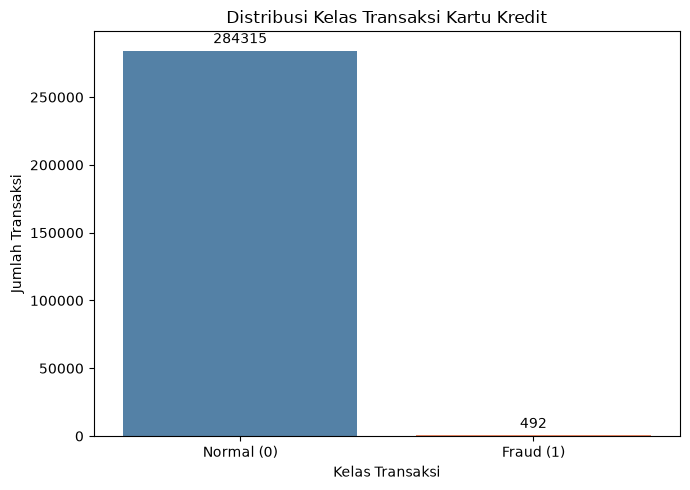

In [7]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x='Class',
    hue='Class',
    palette=['steelblue', 'coral'],
    legend=False
)

plt.title('Distribusi Kelas Transaksi Kartu Kredit')
plt.xlabel('Kelas Transaksi')
plt.ylabel('Jumlah Transaksi')
plt.xticks([0, 1], ['Normal (0)', 'Fraud (1)'])

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.tight_layout()
plt.show()

### Preprocessing

In [8]:
X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data training:", X_train.shape)
print("Data testing :", X_test.shape)

print("\nDistribusi kelas training:")
print(y_train.value_counts())

print("\nDistribusi kelas testing:")
print(y_test.value_counts())

Data training: (227845, 30)
Data testing : (56962, 30)

Distribusi kelas training:
Class
0    227451
1       394
Name: count, dtype: int64

Distribusi kelas testing:
Class
0    56864
1       98
Name: count, dtype: int64


### Baseline model menggunakan Random Forest tanpa SMOTE

In [9]:
rf_baseline = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_baseline.fit(X_train, y_train)

print("Training Random Forest baseline selesai")

Training Random Forest baseline selesai


In [10]:
y_pred_baseline = rf_baseline.predict(X_test)

y_prob_baseline = rf_baseline.predict_proba(X_test)[:, 1]

print("Prediksi berhasil")

Prediksi berhasil


In [11]:
print("=== RANDOM FOREST BASELINE ===")

print("Accuracy :", accuracy_score(y_test, y_pred_baseline))
print("Precision:", precision_score(y_test, y_pred_baseline))
print("Recall   :", recall_score(y_test, y_pred_baseline))
print("F1-Score :", f1_score(y_test, y_pred_baseline))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_baseline))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_baseline))

=== RANDOM FOREST BASELINE ===
Accuracy : 0.9995962220427653
Precision: 0.9411764705882353
Recall   : 0.8163265306122449
F1-Score : 0.8743169398907104
ROC-AUC  : 0.9630272515590367

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.94      0.82      0.87        98

    accuracy                           1.00     56962
   macro avg       0.97      0.91      0.94     56962
weighted avg       1.00      1.00      1.00     56962



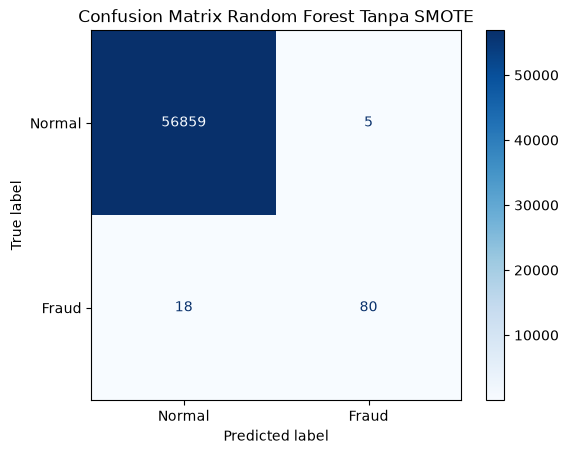

In [12]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_baseline,
    display_labels=['Normal', 'Fraud'],
    cmap='Blues',
    values_format='d'
)

plt.title('Confusion Matrix Random Forest Tanpa SMOTE')
plt.show()

Kesimpulan sementara: Random Forest baseline memberikan performa yang kuat. Namun, recall sebesar 81,63% menunjukkan masih ada 18 dari 98 transaksi fraud yang tidak terdeteksi pada data testing.

Pertanyaan eksperimen berikutnya adalah: apakah SMOTE bisa mengurangi 18 false negative tersebut tanpa meningkatkan false positive terlalu banyak?

### Handling class imbalance dengan SMOTE

In [13]:

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train, y_train
)

print("Sebelum SMOTE:")
print(y_train.value_counts())

print("\nSetelah SMOTE:")
print(y_train_smote.value_counts())

Sebelum SMOTE:
Class
0    227451
1       394
Name: count, dtype: int64

Setelah SMOTE:
Class
0    227451
1    227451
Name: count, dtype: int64


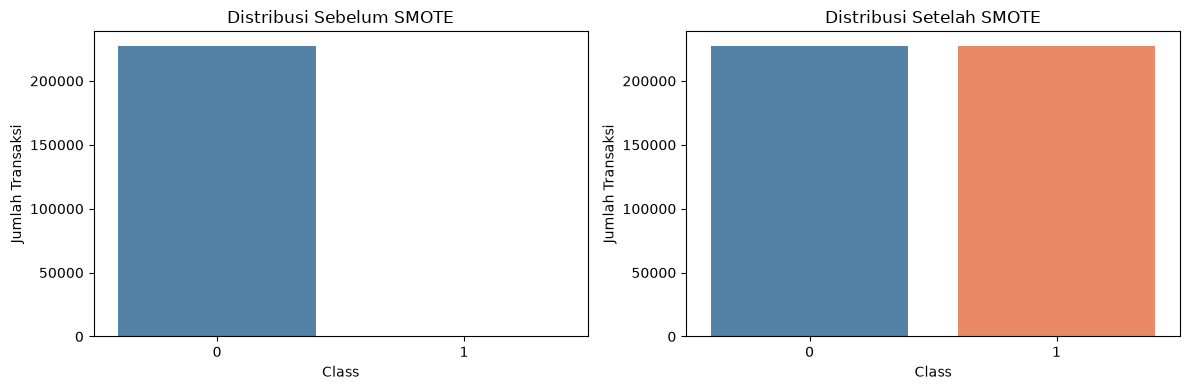

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(
    x=y_train,
    hue=y_train,
    palette=['steelblue', 'coral'],
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Distribusi Sebelum SMOTE')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Jumlah Transaksi')

sns.countplot(
    x=y_train_smote,
    hue=y_train_smote,
    palette=['steelblue', 'coral'],
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Distribusi Setelah SMOTE')
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Jumlah Transaksi')

plt.tight_layout()
plt.show()

In [15]:
rf_smote = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_smote.fit(X_train_smote, y_train_smote)

print("Training Random Forest dengan SMOTE selesai!")

Training Random Forest dengan SMOTE selesai!


In [16]:
y_pred_smote = rf_smote.predict(X_test)

y_prob_smote = rf_smote.predict_proba(X_test)[:, 1]

print("Prediksi dengan SMOTE berhasil!")

Prediksi dengan SMOTE berhasil!


In [17]:
print("=== RANDOM FOREST DENGAN SMOTE ===")

print("Accuracy :", accuracy_score(y_test, y_pred_smote))
print("Precision:", precision_score(y_test, y_pred_smote))
print("Recall   :", recall_score(y_test, y_pred_smote))
print("F1-Score :", f1_score(y_test, y_pred_smote))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_smote))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_smote))

=== RANDOM FOREST DENGAN SMOTE ===
Accuracy : 0.999420666409185
Precision: 0.8350515463917526
Recall   : 0.826530612244898
F1-Score : 0.8307692307692308
ROC-AUC  : 0.9644232605112952

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.84      0.83      0.83        98

    accuracy                           1.00     56962
   macro avg       0.92      0.91      0.92     56962
weighted avg       1.00      1.00      1.00     56962



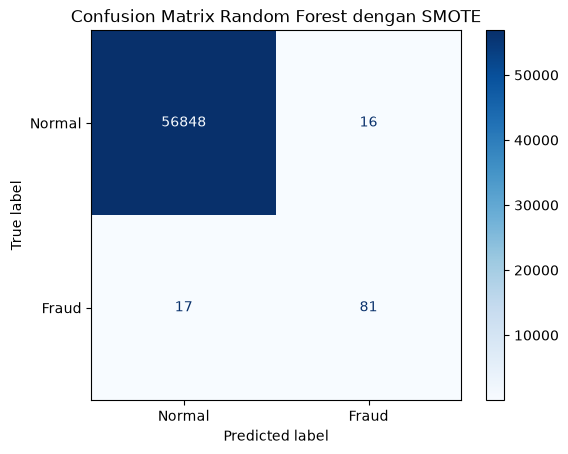

In [18]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_smote,
    display_labels=['Normal', 'Fraud'],
    cmap='Blues',
    values_format='d'
)

plt.title('Confusion Matrix Random Forest dengan SMOTE')
plt.show()

In [21]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Scaling berhasil")

Scaling berhasil


In [22]:
smote_scaled = SMOTE(random_state=42)

X_train_scaled_smote, y_train_scaled_smote = smote_scaled.fit_resample(
    X_train_scaled,
    y_train
)

print("Distribusi setelah Scaling + SMOTE:")
print(y_train_scaled_smote.value_counts())

Distribusi setelah Scaling + SMOTE:
Class
0    227451
1    227451
Name: count, dtype: int64


In [ ]:
rf_scaled_smote = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_scaled_smote.fit(
    X_train_scaled_smote,
    y_train_scaled_smote
)

print("Training Random Forest Scaling + SMOTE selesai")

Training Random Forest Scaling + SMOTE selesai!


In [24]:
y_pred_scaled_smote = rf_scaled_smote.predict(X_test_scaled)
y_prob_scaled_smote = rf_scaled_smote.predict_proba(X_test_scaled)[:, 1]

print("=== RANDOM FOREST + SCALING + SMOTE ===")

print("Accuracy :", accuracy_score(y_test, y_pred_scaled_smote))
print("Precision:", precision_score(y_test, y_pred_scaled_smote))
print("Recall   :", recall_score(y_test, y_pred_scaled_smote))
print("F1-Score :", f1_score(y_test, y_pred_scaled_smote))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_scaled_smote))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_scaled_smote))

=== RANDOM FOREST + SCALING + SMOTE ===
Accuracy : 0.9994908886626171
Precision: 0.8709677419354839
Recall   : 0.826530612244898
F1-Score : 0.8481675392670157
ROC-AUC  : 0.9684509513569075

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.87      0.83      0.85        98

    accuracy                           1.00     56962
   macro avg       0.94      0.91      0.92     56962
weighted avg       1.00      1.00      1.00     56962



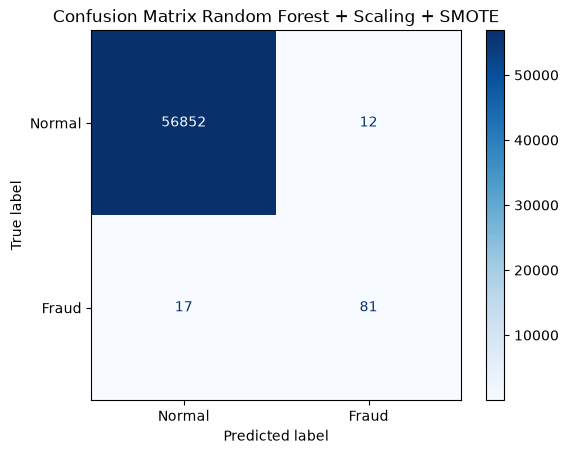

In [25]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_scaled_smote,
    display_labels=['Normal', 'Fraud'],
    cmap='Blues',
    values_format='d'
)

plt.title('Confusion Matrix Random Forest + Scaling + SMOTE')
plt.show()

In [26]:
comparison = pd.DataFrame({
    'Model': [
        'Random Forest Baseline',
        'Random Forest + SMOTE',
        'Random Forest + Scaling + SMOTE'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred_baseline),
        accuracy_score(y_test, y_pred_smote),
        accuracy_score(y_test, y_pred_scaled_smote)
    ],
    'Precision': [
        precision_score(y_test, y_pred_baseline),
        precision_score(y_test, y_pred_smote),
        precision_score(y_test, y_pred_scaled_smote)
    ],
    'Recall': [
        recall_score(y_test, y_pred_baseline),
        recall_score(y_test, y_pred_smote),
        recall_score(y_test, y_pred_scaled_smote)
    ],
    'F1-Score': [
        f1_score(y_test, y_pred_baseline),
        f1_score(y_test, y_pred_smote),
        f1_score(y_test, y_pred_scaled_smote)
    ],
    'ROC-AUC': [
        roc_auc_score(y_test, y_prob_baseline),
        roc_auc_score(y_test, y_prob_smote),
        roc_auc_score(y_test, y_prob_scaled_smote)
    ]
})

display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest Baseline,0.9996,0.9412,0.8163,0.8743,0.9630
1,Random Forest + SMOTE,0.9994,0.8351,0.8265,0.8308,0.9644
2,Random Forest + Scaling + SMOTE,0.9995,0.8710,0.8265,0.8482,0.9685


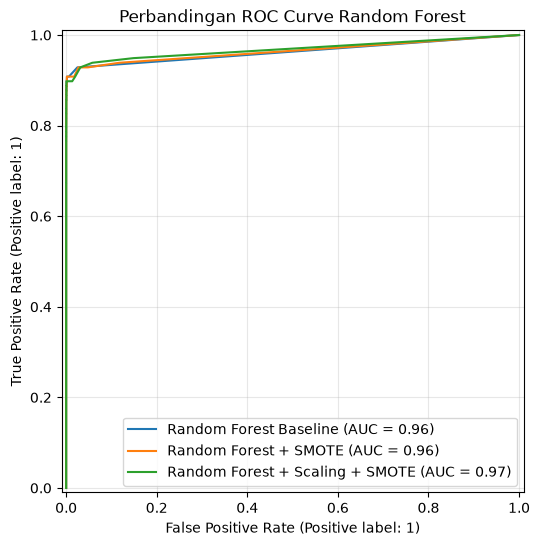

In [27]:
plt.figure(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test, y_prob_baseline,
    name='Random Forest Baseline',
    ax=plt.gca()
)

RocCurveDisplay.from_predictions(
    y_test, y_prob_smote,
    name='Random Forest + SMOTE',
    ax=plt.gca()
)

RocCurveDisplay.from_predictions(
    y_test, y_prob_scaled_smote,
    name='Random Forest + Scaling + SMOTE',
    ax=plt.gca()
)

plt.title('Perbandingan ROC Curve Random Forest')
plt.grid(alpha=0.3)
plt.show()